In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

def fuzzySystem_OP(pixel, vm):

    # pixelIN variables
    x_pixelIN = np.arange(0, 4096, 1)
    #x_grey = np.arange(0, 2, 1)
    x_pixelOUT  = np.arange(0, 2, 1/4096)

    # Generate fuzzy membership functions
    pixelIN_sm = fuzz.trapmf(x_pixelIN, [0, 0, 0.15*vm, 0.6*vm])
    pixelIN_md = fuzz.trimf(x_pixelIN, [0.5*vm, vm, 1.4*vm])
    pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 4095, 4095])
    pixelOUT_sm = fuzz.trapmf(x_pixelOUT, [0, 0, 0.05, 0.1])
    pixelOUT_md = fuzz.trimf(x_pixelOUT, [0.45, 0.5, 0.55])
    pixelOUT_la = fuzz.trapmf(x_pixelOUT, [0.9, 0.95, 1, 1])
    
    # Activation of fuzzy membership functions at vm using fuzz.interp_membership 
    pixelIN_level_sm = fuzz.interp_membership(x_pixelIN, pixelIN_sm, pixel)
    pixelIN_level_md = fuzz.interp_membership(x_pixelIN, pixelIN_md, pixel)
    pixelIN_level_la = fuzz.interp_membership(x_pixelIN, pixelIN_la, pixel)

    # Rules for OP
    rule1 = np.fmin(pixelIN_level_sm, pixelOUT_sm) # edge
    rule2 = np.fmin(pixelIN_level_md, pixelOUT_la) # liver
    rule3 = np.fmin(pixelIN_level_la, pixelOUT_md) # vessel
    
    # Aggregating the output membership functions
    aggregated = np.fmax(rule1, np.fmax(rule2, rule3))
    
    # Calculating the result
    output = fuzz.defuzz(x_pixelOUT, aggregated, 'centroid')
    output_activation = fuzz.interp_membership(x_pixelOUT, aggregated, output) # for plot
    
    return(output)

def fuzzySystem_IP(pixel, vm):

    # pixelIN variables
    x_pixelIN = np.arange(0, 4096, 1)
    x_pixelOUT  = np.arange(0, 2, 1/4096)

    # Generate fuzzy membership functions
    pixelIN_sm = fuzz.trapmf(x_pixelIN, [0, 0, 0.15*vm, 0.6*vm])
    pixelIN_md = fuzz.trimf(x_pixelIN, [0.5*vm, vm, 1.4*vm])
    pixelIN_la = fuzz.trapmf(x_pixelIN, [1.3*vm, 1.6*vm, 4095, 4095])
    pixelOUT_sm = fuzz.trapmf(x_pixelOUT, [0, 0, 0.05, 0.1])
    pixelOUT_md = fuzz.trimf(x_pixelOUT, [0.45, 0.5, 0.55])
    pixelOUT_la = fuzz.trapmf(x_pixelOUT, [0.9, 0.95, 1, 1])

    # Activation of fuzzy membership functions at vm using fuzz.interp_membership 
    pixelIN_level_sm = fuzz.interp_membership(x_pixelIN, pixelIN_sm, pixel)
    pixelIN_level_md = fuzz.interp_membership(x_pixelIN, pixelIN_md, pixel)
    pixelIN_level_la = fuzz.interp_membership(x_pixelIN, pixelIN_la, pixel)
    
    # Rules for IP
    rule1 = np.fmin(pixelIN_level_sm, pixelOUT_md) # vessel
    rule2 = np.fmin(pixelIN_level_md, pixelOUT_la) # liver
    rule3 = np.fmin(pixelIN_level_la, pixelOUT_sm) # edge
    
    # Aggregating the output membership functions
    aggregated = np.fmax(rule1, np.fmax(rule2, rule3))
    
    # Calculating the result
    output = fuzz.defuzz(x_pixelOUT, aggregated, 'centroid')
    output_activation = fuzz.interp_membership(x_pixelOUT, aggregated, output) # for plot
    
    return(output)

## TESTE

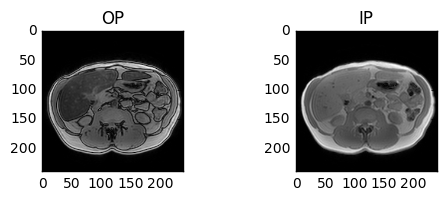

In [2]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

pixelOP = np.genfromtxt("op230.txt")
pixelIP = np.genfromtxt("ip431.txt")

plt.figure(1)

plt.subplot(221)
plt.imshow(pixelOP, cmap='gray')
plt.title('OP')

plt.subplot(222)
plt.imshow(pixelIP, cmap='gray')
plt.title('IP')

plt.show()

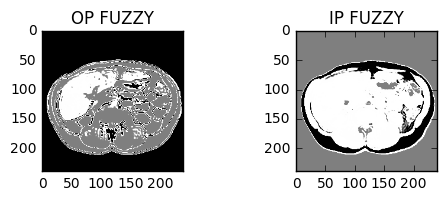

In [3]:
imgOP = np.zeros(pixelOP.shape)
imgIP = np.zeros(pixelIP.shape)

for index, pixel in np.ndenumerate(pixelOP):
    imgOP[index] = fuzzySystem_OP(pixel, 230)

for index, pixel in np.ndenumerate(pixelIP):
    imgIP[index] = fuzzySystem_IP(pixel, 431)
    
plt.figure(1)

plt.subplot(221)
plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')

plt.subplot(222)
plt.imshow(imgIP, cmap='gray')
plt.title('IP FUZZY')

plt.show()

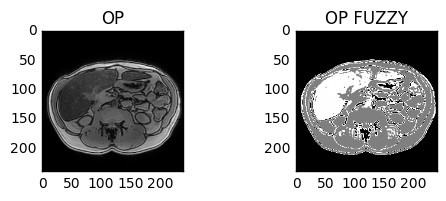

In [4]:
plt.figure(1)

plt.subplot(221)
plt.imshow(pixelOP, cmap='gray')
plt.title('OP')

plt.subplot(222)
plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')

plt.show()

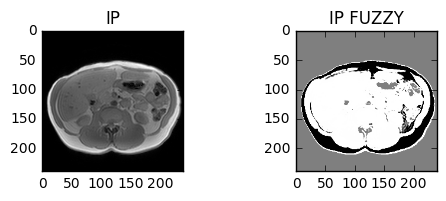

In [5]:
plt.figure(1)

plt.subplot(221)
plt.imshow(pixelIP, cmap='gray')
plt.title('IP')

plt.subplot(222)
plt.imshow(imgIP, cmap='gray')
plt.title('IP FUZZY')

plt.show()

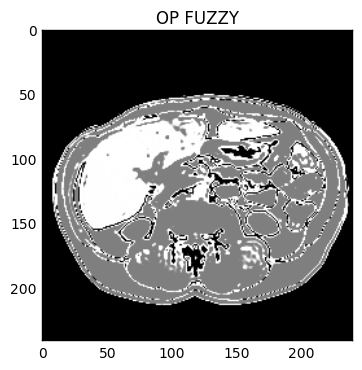

In [9]:
plt.imshow(imgOP, cmap='gray')
plt.title('OP FUZZY')
plt.show()

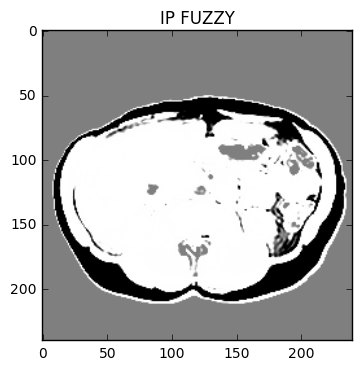

In [8]:
plt.imshow(imgIP, cmap='gray')
plt.title('IP FUZZY')
plt.show()